In [7]:
!python --version

Python 3.12.12


### Negative Binomial

Let's simulate 

- λ ~ Gamma(shape 1/φ, scale φμ), 

- then Y | λ ~ Poisson(λ). 
- Let's compare the result with the analytic negative binomial pmf and check that the variance follows μ + φμ², where φ = 1/r.


The simulation confirms that drawing a Gamma rate and then a Poisson count gives exactly the negative binomial, with variance μ + φμ².

![Gamma–Poisson simulation: (a) latent rates, (b) mixture vs analytic NB vs Poisson, (c) mean–variance across simulated genes](../figures/negative_binomial_simulation.png)

### Setup

- For one "gene" I set μ = 10 and φ = 0.5, so the Gamma shape is r = 1/φ = 2.

- Drew 200,000 rates λ ~ Gamma(shape 2, scale φμ = 5)
- then one count per rate, Y ~ Poisson(λ).

#### **Panel a, the rates.** 

The latent rates have mean 9.96 and variance 49.4; theory gives 10 and φμ² = 50. The distribution is strongly right-skewed, so most observations have a low rate and a few have a very high one.

####  **Panel b, the mixture is the negative binomial.**

- The simulated count distribution and the analytic NB(μ = 10, φ = 0.5) pmf differ by at most **0.0009** at any count.

- The counts have variance **59.3**, against a theoretical μ + φμ² = 60. A Poisson with the same mean would have variance 10.
- The grey Poisson(10) curve is much narrower. The biggest difference is at zero: P(Y = 0) is **0.0275** in the simulation and **0.0278** under the NB, but only **0.000045** under the Poisson. Rate variation alone produces about 600× more zeros. This is why many "dropouts" in scRNA-seq do not need a separate zero-inflation component.

#### **Panel c, the mean–variance relationship.** 

Simulation of 400 genes with means from 0.1 to about 300, using 2,000 cells per gene, at three dispersion values:

- **φ = 0 (pure Poisson):** variance equals the mean, a straight line of slope 1 on the log–log plot.

- **φ = 0.1 and φ = 1:** variance follows μ at low means and bends towards φμ² at high means. The bend happens near μ ≈ 1/φ, where the biological (Gamma) term overtakes the counting (Poisson) term.

- Estimated φ back from the simulated genes with mean > 1 using the moment estimator (variance − mean)/mean².

- The medians were 0.000, 0.100 and 0.995, matching the true values of 0, 0.1 and 1.
- This is essentially how DESeq2, edgeR and sctransform estimate dispersion for each gene before shrinking those estimates.

In [8]:
import os, sys
from pathlib import Path
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt, matplotlib as mpl

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.matplotlib_figure_style import *

In [17]:
root_source = ROOT0 / 'notebooks_multiproject'
root_figure = root_source/ 'figures'

In [10]:
apply_figure_style()

### numpy.random.default_rng()

numpy.random.default_rng() is the recommended constructor used to initialize a new random number Generator in modern NumPy (version 1.17 and later). It replaces the legacy numpy.random.seed() and np.random.RandomState approaches by providing isolated, thread-safe, and statistically superior pseudo-random number

In [11]:
rng = np.random.default_rng(1)
rng

Generator(PCG64) at 0x7A4A2B95E340

In [14]:
# ---- Panel a/b: one "gene", mu=10, phi=0.5 ----
mu, phi, N = 10.0, 0.5, 200_000

r = 1/phi

rand_gamma = rng.gamma(shape=r, scale=phi*mu, size=N)
rand_poi = rng.poisson(rand_gamma)

p=1/(1+phi*mu)
nb = stats.nbinom(n=r, p=p)
print(f"r={r:<5.2f} -> therefore phi={phi:<5.2f}, p=1/(1+phi*mu)={p:<5.2f}")

ks = np.arange(0, 61)
emp = np.bincount(rand_poi, minlength=ks.max()+1)[:ks.size]/N
print(f"lambda: mean={rand_gamma.mean():.3f} var={rand_gamma.var():.3f} (theory {mu}, {phi*mu**2})")
print(f"Poisson Y: mean={rand_poi.mean():.3f} var={rand_poi.var():.3f} (theory {mu}, {mu+phi*mu**2})")
print(f"max |emp - NB pmf| = {np.abs(emp-nb.pmf(ks)).max():.4f}")
print(f"P(Y=0): sim={np.mean(rand_poi==0):.4f} NB={nb.pmf(0):.4f} Poisson={stats.poisson(mu).pmf(0):.6f}")

# ---- Panel c: mean-variance across 400 genes, several phi ----
mus = np.logspace(-1, 2.5, 400); ncell = 2000


r=2.00  -> therefore phi=0.50 , p=1/(1+phi*mu)=0.17 
lambda: mean=10.005 var=49.825 (theory 10.0, 50.0)
Poisson Y: mean=10.009 var=59.842 (theory 10.0, 60.0)
max |emp - NB pmf| = 0.0009
P(Y=0): sim=0.0273 NB=0.0278 Poisson=0.000045


In [15]:
res = {}
for ph in [0.0, 0.1, 1.0]:
    m_, v_ = [], []
    for m in mus:
        l = np.full(ncell, m) if ph == 0 else rng.gamma(1/ph, ph*m, ncell)
        c = rng.poisson(l); m_.append(c.mean()); v_.append(c.var(ddof=1))
    res[ph] = (np.array(m_), np.array(v_))
    m_, v_ = res[ph]; ok = m_ > 0
    # moment estimate of phi from simulated genes with mean>1
    sel = m_ > 1
    est = np.median((v_[sel]-m_[sel])/m_[sel]**2)
    print(f"phi={ph}: median moment-estimate phi = {est:.3f}")

phi=0.0: median moment-estimate phi = 0.000
phi=0.1: median moment-estimate phi = 0.101
phi=1.0: median moment-estimate phi = 0.999


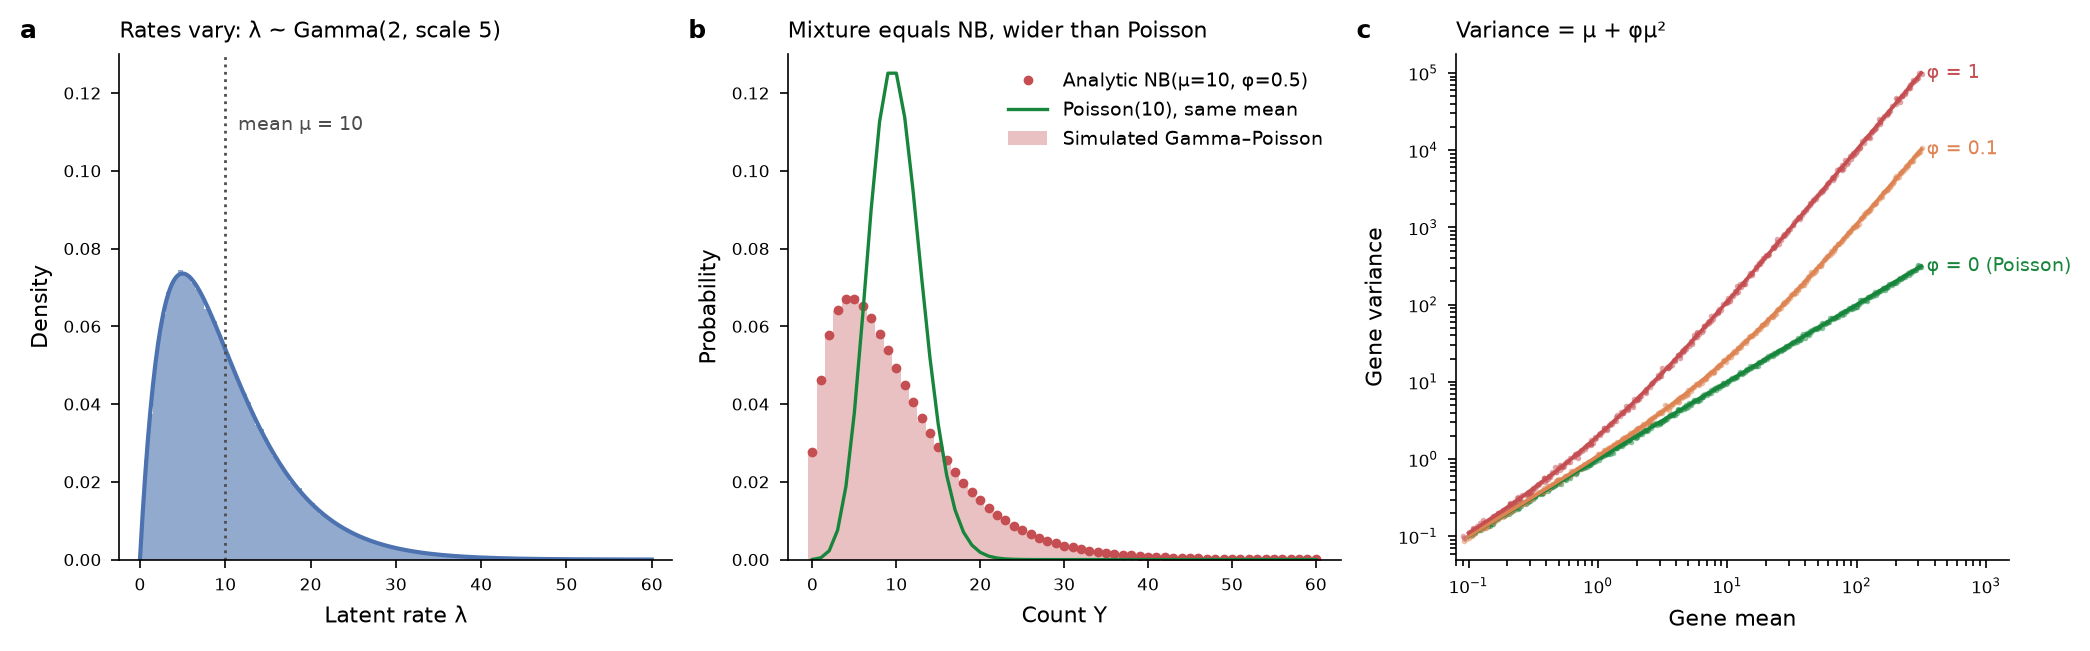

In [22]:


fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.3))

c_gam, c_nb, c_poi = "#4C72B0", "#C44E52", "#17863C"

ax = axs[0]
ax.hist(rand_gamma, bins=120, range=(0, 60), density=True, color=c_gam, alpha=0.6)
xx = np.linspace(0.01, 60, 400)
ax.plot(xx, stats.gamma(a=r, scale=phi*mu).pdf(xx), color=c_gam, lw=1.5)
ax.axvline(mu, color="0.3", ls=":", lw=1)
ax.set(xlabel="Latent rate λ", ylabel="Density", title="Rates vary: λ ~ Gamma(2, scale 5)")
ax.set_ylim(0, 0.13)
ax.text(mu+1.5, ax.get_ylim()[1]*0.85, "mean μ = 10", fontsize=7, color="0.3")

ax = axs[1]
ax.bar(ks, emp, width=1.0, color=c_nb, alpha=0.35, label="Simulated Gamma–Poisson")
ax.plot(ks, nb.pmf(ks), "o", ms=2.5, color=c_nb, label="Analytic NB(μ=10, φ=0.5)")
ax.plot(ks, stats.poisson(mu).pmf(ks), "-", color=c_poi, lw=1.2, label="Poisson(10), same mean")
ax.set(xlabel="Count Y", ylabel="Probability", title="Mixture equals NB, wider than Poisson")
ax.set_ylim(0, 0.13)
ax.legend(frameon=False, fontsize=7, loc="upper right")

ax = axs[2]
cols = {0.0: c_poi, 0.1: "#DD8452", 1.0: c_nb}
for ph, (m_, v_) in res.items():
    ok = (m_ > 0) & (v_ > 0)
    ax.scatter(m_[ok], v_[ok], s=4, color=cols[ph], alpha=0.5, lw=0)
    mm = np.logspace(-1, 2.5, 100)
    ax.plot(mm, mm+ph*mm**2, color=cols[ph], lw=1.3)
    ax.text(mm[-1]*1.1, (mm+ph*mm**2)[-1], f"φ = {ph:g}" + (" (Poisson)" if ph == 0 else ""),
            color=cols[ph], fontsize=7, va="center")
ax.set(xscale="log", yscale="log", xlabel="Gene mean", ylabel="Gene variance",
       title="Variance = μ + φμ²", xlim=(0.08, 1500))
for a in axs: a.margins(0.04)
for a, L in zip(axs, "abc"): panel_letter(a, L)
fig.tight_layout()

filefig = root_figure / "gamma_poisson_simulation.png"
fig.savefig(filefig, dpi=300)